# HW3P2: Automatic Speech Recognition with an Encoder-Decoder Transformer

# Schedule:
- Kaggle Submission (DUE 6 November 2026 @ 11:59PM EST | Slack Deadline is 13 November 2026 @ 11:59PM EST)
- Code Submission (DUE 8 November 2026 @ 11:59PM EST | Closes 13 November 2026 @ 11:59PM EST, with the Slack Kaggle Competition)


## Requirement Acknowledgement

Setting the flag below to **True** indicates that you have read, understood, and agree to comply with **all** of the following requirements:

1. **Slack Days Usage**  
   Slack days may be used **only** for the **P2 Final submission**.  
   Specifically, slack days may be applied to submit **final P2 Kaggle scores** to the **Slack Kaggle Competition**, at the expense of your available slack days.

2. **Final Code Submission Deadline**  
   The final **Gradescope code submission** is due **within 48 hours after** the Kaggle competition deadline.

3. **Kaggle Username & Score Verification**  
   You must provide your **Kaggle username** below. We will use it to retrieve your official **PRIVATE leaderboard** score.  
   Minor score or output variance is acceptable; however, any discrepancies caused by **modifications to the required submission code**
   (including the notebook’s final submission cell) will result in an **Academic Integrity Violation (AIV)**.

4. **Model Implementation Restrictions**  
   You are **not permitted** to use pre-trained or pre-loaded models (e.g., from Hugging Face or similar libraries).  
   You **may** implement models described in research papers or articles, but they **must** be implemented **from scratch**
   using fundamental PyTorch components (e.g., `Linear`, `Conv2d`, etc.).

5. **Data Usage Restrictions**  
   The use of **any external data or datasets** is strictly prohibited at **any stage** of this assignment.

6. **Collaboration Policy**  
   You may collaborate with teammates to run experiments or ablations.  
   However, you must submit **your own code** and **your own results**.

7. **Academic Integrity**  
   Failure to comply with any of the above requirements will be treated as an **Academic Integrity Violation (AIV)**.

8. **Late Submissions**  
   Late submissions **must** be submitted through the **Slack Kaggle Competition** (see write-up for details).  
   Submissions made to the **regular Kaggle competition** after the original deadline will **not** be considered,
   regardless of remaining slack days.
   
   Gradescope code submission will close at **the same time** as the Slack Kaggle Competition, rather than remaining open for an additional 48 hours.


In [1]:
ACKNOWLEDGED = True #TODO: Only set Acknowledged to True if you have read the above acknowlegements and agree to ALL of them.

# Setup
-  Follow the setup instructions based on your preferred environment!

Click [**HERE**](https://www.kaggle.com/t/6aedc76c79fa415fb477f967ffd7c799) to join the HW3P2 Kaggle competition first!

## Local

One of our key goals in designing this assignment is to allow you to complete most of the preliminary implementation work locally.  
We highly recommend that you **pass all tests locally** using the provided `hw3_data_subset` before moving to a GPU runtime.  
To do this, simply:

### Create a new conda environment
```bash
# Be sure to deactivate any active environments first
conda create -n hw3 python=3.12.4
```

### Activate the conda environment
```bash
conda activate hw3
```

### Install the dependencies using the provided `requirements.txt`
```bash
pip install --no-cache-dir --ignore-installed -r requirements.txt
```

### Ensure that your notebook is in the same working directory as the `Handout`
This can be achieved by:
1. Physically moving the notebook into the handout directory.
2. Changing the notebook’s current working directory to the handout directory using the os.chdir() function.

### Open the notebook and select the newly created environment from the kernel selector.

If everything was done correctly, You should see atleast the following files in your current working directory after running `!ls`:
```
.
├── README.md
├── requirements.txt
├── hw3lib/
├── tests/
└── hw3_data_subset/
```

## Colab

### Step 1: Get your handout
- See writeup for recommended approaches.

In [2]:
# Example: My preferred approach
import os
# Settings -> Developer Settings -> Personal Access Tokens -> Token (classic)
from getpass import getpass
os.environ['GITHUB_TOKEN'] = getpass("GitHub token: ")

GITHUB_USERNAME = "macregis1"
REPO_NAME       = "IDL-HW3" # TODO: Your repo's name. The cells below use this variable, so set it here only
TOKEN = os.environ.get("GITHUB_TOKEN")
repo_url        = f"https://{TOKEN}@github.com/{GITHUB_USERNAME}/{REPO_NAME}.git"
!git clone {repo_url}

fatal: destination path 'IDL-HW3' already exists and is not an empty directory.


In [3]:
# To pull latest changes (Must be in the repo dir, use pwd/ls to verify)
!cd {REPO_NAME} && git pull

Already up to date.


### Step 2: Install Dependencies
- `NOTE`: Colab already has PyTorch and most of what this homework needs, so this only installs the packages it is missing.
- `NOTE`: Do not install `requirements.txt` on Colab. It pins versions for the local setup, and Colab's Python cannot install some of them.

In [54]:
!pwd
%cd /content/

/content/IDL-HW3
/content


In [5]:
!pip install wandb==0.23.1 torchinfo torchmetrics kaggle==1.8.0 "kagglehub>=1.0.0" --quiet

### Step 3: Configure Kaggle API Access

⚠️ **Important:** You must provide your own Kaggle API credentials while creating your deliverables for code submission and (optionally) submitting to the competition.

#### How to obtain your Kaggle API credentials

1. Navigate to your **Kaggle Profile → Settings** tab.
2. Click **“Generate New Token”**
3. Copy the token and paste it below. It is `KGAT_` followed by 32 letters and digits, for example `KGAT_0123456789abcdef0123456789abcdef`. The older 32-character key inside a `kaggle.json` file is a different credential and does not work here.
4. Set `KAGGLE_USERNAME` to your Kaggle username, as shown on your profile page, not your email address.

Join the HW3P2 kaggle competition (https://www.kaggle.com/t/6aedc76c79fa415fb477f967ffd7c799)

In [6]:
import os
import pprint
os.environ['KAGGLE_USERNAME'] = "regisndahirongoga" # TODO: Verify in Settings
from getpass import getpass
os.environ['KAGGLE_API_TOKEN'] = getpass("Kaggle KGAT_ token: ") # TODO: Add your API token, KGAT_ followed by 32 letters and digits

# The new API token starts with KGAT_. The 32-character key in an older kaggle.json does not work here.
os.environ['KAGGLE_API_TOKEN'] = os.environ['KAGGLE_API_TOKEN'].strip()
assert os.environ['KAGGLE_API_TOKEN'].startswith("KGAT_"), "Use the API token that starts with KGAT_ (Kaggle Profile → Settings → Generate New Token)"

# Verify
import kaggle
api = kaggle.api  # Already authenticated on import
api.competitions_list_cli()

ref                                                                           deadline             category         reward  teamCount  userHasEntered  
----------------------------------------------------------------------------  -------------------  --------  -------------  ---------  --------------  
https://www.kaggle.com/competitions/passenger-screening-algorithm-challenge   2017-12-15 23:59:00  Featured  1,500,000 Usd        518           False  
https://www.kaggle.com/competitions/zillow-prize-1                            2018-01-10 15:59:00  Featured  1,200,000 Usd       3770           False  
https://www.kaggle.com/competitions/data-science-bowl-2017                    2017-04-12 23:59:00  Featured  1,000,000 Usd       1972           False  
https://www.kaggle.com/competitions/vesuvius-challenge-ink-detection          2023-06-14 23:59:00  Featured  1,000,000 Usd       1249           False  
https://www.kaggle.com/competitions/arc-prize-2026-arc-agi-3                  2026-11-02

### Step 4: Obtain Data
- `NOTE`: This downloads the `HW3P2` dataset from Kaggle and unzips it to `/content/hw3p2-data/hw3p2_data`.

In [9]:
!curl -L -o /content/f26-hw3p2-data.zip https://www.kaggle.com/api/v1/datasets/download/cmu11785/f26-hw3p2-data
!unzip -q -o /content/f26-hw3p2-data.zip -d /content
!rm -rf /content/f26-hw3p2-data.zip
!du -h --max-depth=2 /content/hw3p2-data/hw3p2_data

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 11.8G  100 11.8G    0     0  40.5M      0  0:04:58  0:04:58 --:--:-- 40.8M
748M	/content/hw3p2-data/hw3p2_data/test-clean/fbank
748M	/content/hw3p2-data/hw3p2_data/test-clean
11M	/content/hw3p2-data/hw3p2_data/dev-clean/text
747M	/content/hw3p2-data/hw3p2_data/dev-clean/fbank
757M	/content/hw3p2-data/hw3p2_data/dev-clean
113M	/content/hw3p2-data/hw3p2_data/train-clean-100/text
14G	/content/hw3p2-data/hw3p2_data/train-clean-100/fbank
14G	/content/hw3p2-data/hw3p2_data/train-clean-100
16G	/content/hw3p2-data/hw3p2_data


### Step 5: Move to Handout Directory
You must be within the handout directory for the library imports to work!

- `NOTE`: You may have to repeat running this command anytime you restart your runtime.
- `NOTE`: You can do a `pwd` to check if you are in the right directory.
- `NOTE`: Your data is in `/content/hw3p2-data/hw3p2_data`. Use this path for `root` in the config file.

If everything was done correctly, You should see atleast the following files in your current working directory after running `!ls`:
```
.
├── README.md
├── requirements.txt
├── hw3lib/
├── tests/
└── hw3_data_subset/

```

In [10]:
import os
os.chdir(REPO_NAME)  # Set when you cloned the repo. After a restart, run that cell again first
!ls

config.yaml  hw3_data_subset  README.md		tests
expts	     hw3lib	      requirements.txt	wandb


## Kaggle

While it is possible to run the notebook on Kaggle, we would recommend against it. This assignment is more resource intensive and may run slower on Kaggle.

- `NOTE`: Turn on `Internet` in the notebook settings. Getting your handout and installing the dependencies both need it.

### Step 1: Get your handout
- See writeup for recommended approaches.

In [ ]:
# Example: My preferred approach
import os
# Settings -> Developer Settings -> Personal Access Tokens -> Token (classic)
from getpass import getpass
os.environ['GITHUB_TOKEN'] = getpass("GitHub token: ")

GITHUB_USERNAME = "macregis1"
REPO_NAME       = "IDL-HW3" # TODO: Your repo's name. The cells below use this variable, so set it here only
TOKEN = os.environ.get("GITHUB_TOKEN")
repo_url        = f"https://{TOKEN}@github.com/{GITHUB_USERNAME}/{REPO_NAME}.git"
!git clone {repo_url}

In [ ]:
# To pull latest changes (Must be in the repo dir, use pwd/ls to verify)
!cd {REPO_NAME} && git pull

### Step 2: Install Dependencies

In [21]:
!pip install wandb==0.23.1 torchinfo torchmetrics kaggle==1.8.0 "kagglehub>=1.0.0" --quiet

### Step 3: Get Data

If you are using Kaggle, do not download the data manually. Follow these steps to add the dataset directly to your notebook:
1. Open your **Kaggle Notebook**.
2. Navigate to **Notebook → Input**.
3. Click **Add Input**.
4. Search for the dataset `cmu11785/f26-hw3p2-data` (https://www.kaggle.com/datasets/cmu11785/f26-hw3p2-data).
5. Click the **➕ (plus sign)** to add the dataset to your notebook.

Then run the cell below. It prints where Kaggle put the data; use that path for `root` in the config file.

In [22]:
import glob
# The handout ships a small hw3_data_subset/hw3p2_data of its own, which is not the dataset
print([p for p in glob.glob('/kaggle/input/**/hw3p2_data', recursive=True) if 'hw3_data_subset' not in p])

[]


### Step 4: Configure Kaggle API Access

⚠️ **Important:** You must provide your own Kaggle API credentials while creating your deliverables for code submission and (optionally) submitting to the competition.

#### How to obtain your Kaggle API credentials

1. Navigate to your **Kaggle Profile → Settings** tab.
2. Click **“Generate New Token”**
3. Copy the token and paste it below. It is `KGAT_` followed by 32 letters and digits, for example `KGAT_0123456789abcdef0123456789abcdef`. The older 32-character key inside a `kaggle.json` file is a different credential and does not work here.
4. Set `KAGGLE_USERNAME` to your Kaggle username, as shown on your profile page, not your email address.

Join the HW3P2 kaggle competition (https://www.kaggle.com/t/6aedc76c79fa415fb477f967ffd7c799)

In [ ]:
import os
import pprint
os.environ['KAGGLE_USERNAME'] = "<your-username>" # TODO: Verify in Settings
os.environ['KAGGLE_API_TOKEN'] = "<your-key>" # TODO: Add your API token, KGAT_ followed by 32 letters and digits

# The new API token starts with KGAT_. The 32-character key in an older kaggle.json does not work here.
os.environ['KAGGLE_API_TOKEN'] = os.environ['KAGGLE_API_TOKEN'].strip()
assert os.environ['KAGGLE_API_TOKEN'].startswith("KGAT_"), "Use the API token that starts with KGAT_ (Kaggle Profile → Settings → Generate New Token)"

# Verify
import kaggle
api = kaggle.api  # Already authenticated on import
api.competitions_list_cli()

### Step 5: Move to Handout Directory
You must be within the handout directory for the library imports to work!

- `NOTE`: You may have to repeat running this command anytime you restart your session.
- `NOTE`: You can do a `pwd` to check if you are in the right directory.

In [ ]:
import os
os.chdir(REPO_NAME)  # Set when you cloned the repo. After a restart, run that cell again first
!ls

## PSC

### Step 1: Setting Up Your Environment on Bridges2

❗️⚠️ For this homework, we are **providing a shared Conda environment** for the entire class. Therefore, PSC users **do not need to manually install any packages**.

❗️⚠️ For this homework, there is **no shared copy of the dataset on PSC**. You need to **download it from Kaggle to the node `$LOCAL`** to avoid I/O bottlenecks from the shared filesystem. This means that each time you run on a new node, you need to download the dataset again. However, as long as you stay on the same node, you do not need to re-download the dataset. Please refer to **Step 4** for the detailed procedure.

Follow these steps to set up the environment and start a Jupyter notebook on Bridges2:

- To run your notebook more efficiently on PSC, we need to use a **Jupyter Server** hosted on a compute node.

- You can use your prefered way of connecting to the Jupyter Server.  **The recommended way is to connect in VSCode.**
Follow the instructions below.

#### **Connect in VSCode**
SSH into Bridges2 and navigate to your **Jet directory** (`/jet/home/<your_username>`). Upload your notebook there, and then connect to the Jupyter Server from that directory.

#### **1.1 SSH into Bridges2**
1）Open VS Code and click on the `Extensions` icon in the left sidebar. Make sure the "**Remote - SSH**" extension is installed.

2）Open the command palette (**Shift+Command+P** on Mac, **Ctrl+Shift+P** on Windows). A search box will appear at the top center. Choose `"Remote-SSH: Add New SSH Host"`, then enter:

```bash
ssh <your_username>@bridges2.psc.edu #change <your_username> to your username
```

Next, choose `"/Users/<your_username>/.ssh/config"` as the config file. A dialog will appear in the bottom right saying "Host Added". Click `"Connect"`, and then enter your password.

(Note: After adding the host once, you can later use `"Remote-SSH: Connect to Host"` and select "bridges2.psc.edu" from the list.)

3）Once connected, click `"Explorer"` in the left sidebar > "Open Folder", and navigate to your home directory under the project grant:
```bash
/jet/home/<your_username>  #change <your_username> to your username
```

4）You can now drag your notebook files directly into the right-hand pane (your remote home directory), or upload them using `scp` into your folder.

> ❗️⚠️ The following steps should be executed in the **VSCode integrated terminal**.

#### **1.2 Navigate to Your Directory**
Make sure to use this `/jet/home/<your_username>` as your working directory, since all subsequent operations (up to submission) are based on this path.
```bash
cd /jet/home/<your_username>  #change <your_username> to your username
```

#### **1.3 Request a Compute Node**
```bash
interact -p GPU-shared --gres=gpu:v100-32:1 -t 8:00:00 -A cis250019p
```

#### **1.4 Load the Anaconda Module**
```bash
module load anaconda3
```

#### **1.5 Activate the provided HW Environment**
```bash
conda deactivate # First, deactivate any existing Conda environment
conda activate /ocean/projects/cis250019p/mzhang23/TA/envs/IDLF26 && export PYTHONNOUSERSITE=1
```

#### **1.6 Start Jupyter Notebook**
Launch Jupyter Notebook:
```bash
jupyter notebook --no-browser --ip=0.0.0.0
```

Go to **Kernel** → **Select Another Kernel** → **Existing Jupyter Server**
   Enter the URL of the Jupyter Server:```http://{hostname}:{port}/tree?token={token}```
   
   *(Usually, this URL appears in the terminal output after you run `jupyter notebook --no-browser --ip=0.0.0.0`, in a line like:  “Jupyter Server is running at: http://...”)*

   - eg: `http://v011.ib.bridges2.psc.edu:8888/tree?token=e4b302434e68990f28bc2b4ae8d216eb87eecb7090526249`

> **Note**: Replace `{hostname}`, `{port}` and `{token}` with your actual values from the Jupyter output.

After launching the Jupyter notebook, you can run the cells directly inside the notebook — no need to use the terminal for the remaining steps.

### Step 2: Get Repo

In [ ]:
#Make sure you are in your directory
!pwd #should be /jet/home/<your_username>, if not, uncomment the following line and replace with your actual username:
# %cd /jet/home/<your_username>
#TODO: replace the "<your_username>" to yours

In [ ]:
# Example: My preferred approach
import os
# Settings -> Developer Settings -> Personal Access Tokens -> Token (classic)
os.environ['GITHUB_TOKEN'] = "your_github_token_here"

GITHUB_USERNAME = "your_github_username_here"
REPO_NAME       = "IDL-HW3" # TODO: Your repo's name. The cells below use this variable, so set it here only
TOKEN = os.environ.get("GITHUB_TOKEN")
repo_url        = f"https://{TOKEN}@github.com/{GITHUB_USERNAME}/{REPO_NAME}.git"
!git clone {repo_url}

In [ ]:
# To pull latest changes (Must be in the repo dir, use pwd/ls to verify)
!cd {REPO_NAME} && git pull

#### **Move to Project Directory**
- `NOTE`: You may have to repeat this on anytime you restart your runtime. You can do a `pwd` or `ls` to check if you are in the right directory.

In [ ]:
import os
os.chdir(REPO_NAME)  # Set when you cloned the repo. After a restart, run that cell again first
!ls

### Step 3: Configure Kaggle API Access

⚠️ **Important:** You must provide your own Kaggle API credentials for data downloads, while creating your deliverables for code submission and (optionally) submitting to the competition.

#### How to obtain your Kaggle API credentials

1. Navigate to your **Kaggle Profile → Settings** tab.
2. Click **“Generate New Token”**
3. Copy the token and paste it below. It is `KGAT_` followed by 32 letters and digits, for example `KGAT_0123456789abcdef0123456789abcdef`. The older 32-character key inside a `kaggle.json` file is a different credential and does not work here.
4. Set `KAGGLE_USERNAME` to your Kaggle username, as shown on your profile page, not your email address.

Join the HW3P2 kaggle competition (https://www.kaggle.com/t/6aedc76c79fa415fb477f967ffd7c799)

In [24]:
import os
import pprint
os.environ['KAGGLE_USERNAME'] = "regisndahirongoga" # TODO: Verify in Settings
from getpass import getpass
os.environ['KAGGLE_API_TOKEN'] = getpass("Kaggle KGAT_ token: ") # TODO: Add your API token, KGAT_ followed by 32 letters and digits

# The new API token starts with KGAT_. The 32-character key in an older kaggle.json does not work here.
os.environ['KAGGLE_API_TOKEN'] = os.environ['KAGGLE_API_TOKEN'].strip()
assert os.environ['KAGGLE_API_TOKEN'].startswith("KGAT_"), "Use the API token that starts with KGAT_ (Kaggle Profile → Settings → Generate New Token)"

# Verify
import kaggle
api = kaggle.api  # Already authenticated on import
api.competitions_list_cli()

ref                                                                           deadline             category         reward  teamCount  userHasEntered  
----------------------------------------------------------------------------  -------------------  --------  -------------  ---------  --------------  
https://www.kaggle.com/competitions/passenger-screening-algorithm-challenge   2017-12-15 23:59:00  Featured  1,500,000 Usd        518           False  
https://www.kaggle.com/competitions/zillow-prize-1                            2018-01-10 15:59:00  Featured  1,200,000 Usd       3770           False  
https://www.kaggle.com/competitions/data-science-bowl-2017                    2017-04-12 23:59:00  Featured  1,000,000 Usd       1972           False  
https://www.kaggle.com/competitions/vesuvius-challenge-ink-detection          2023-06-14 23:59:00  Featured  1,000,000 Usd       1249           False  
https://www.kaggle.com/competitions/arc-prize-2026-arc-agi-3                  2026-11-02

### Step 4: Get Data

❗️⚠️ In this homework, you need to download the dataset to the **GPU node’s local storage (`$LOCAL`)** instead of your `/jet` or `/ocean` directories, in order to avoid I/O bottlenecks. Using the shared filesystem may slow down training drastically and can take hours per epoch.

Note that **the local storage on a compute node is temporary and will be cleared** when your node time limit is reached or when you move to a different node. Therefore, **every time you run on a new node, you need to re-run the dataset download step**. However, as long as you stay on the same node, you do NOT need to download the dataset again.

In [26]:
api.dataset_download_files(
    "cmu11785/f26-hw3p2-data",
    path=f"{os.environ['LOCAL']}",
    unzip=True
)

KeyError: 'LOCAL'

In [ ]:
import os
data_path = "/local/hw3p2-data/hw3p2_data" # this is the path of the dataset on your node
print("Files in your hw3p2 dataset:", os.listdir(data_path))

In [ ]:
!tree -L 2 /local/hw3p2-data/hw3p2_data | head -n 20

# Imports
- If your setup was done correctly, you should be able to run the following cell without any issues.

In [11]:
from hw3lib.data import (
    H3Tokenizer,
    ASRDataset,
    verify_dataloader
)
from hw3lib.model import (
    EncoderDecoderTransformer
)
from hw3lib.utils import (
    create_scheduler,
    create_optimizer,
    plot_lr_schedule
)
from hw3lib.trainers import (
    ASRTrainer,
    ProgressiveTrainer
)
from torch.utils.data import DataLoader
import yaml
import gc
import torch
from torchinfo import summary
import os
import json
import wandb
import pandas as pd
device = "cuda" if torch.cuda.is_available() else "cpu"


# Implementations
- `NOTE`: All of these implementations have detailed specification, implementation details, and hints in their respective source files. Make sure to read all of them in their entirety to understand the implementation details!

## Dataset Implementation
- Implement the `ASRDataset` class in `hw3lib/data/asr_dataset.py`.
- You will have to implement parts of `__init__` and completely implement the `__len__`, `__getitem__` and `collate_fn` methods.
- Run the cell below to check your implementation.


In [12]:
!python -m tests.test_dataset_asr

Loading data for train-clean-100 partition...
100% 28/28 [00:00<00:00, 780.01it/s]
Loading data for test-clean partition...
100% 2/2 [00:00<00:00, 3664.75it/s]

Running tests for category: ASRDataset Train
--------------------------------------------------------------------------------

[01/01]    Running:  Test a Train instance of ASRDataset class
Testing __init__ method ...
Test Passed: Dataset length matches FBANK files.
Test Passed: Dataset length matches TRANSCRIPT files.
Test Passed: Order alignment between FBANK files and TRANSCRIPT files is correct.
Test Passed: Alignment between features and transcripts is correct.
Test Passed: All features have the correct number of dimensions (num_feats).
Test Passed: All transcripts are decoded correctly after removing SOS and EOS tokens.
Testing __getitem__ method ...
Test Passed: All samples have correct feature dimensions and transcript alignment.
Testing collate_fn method ...
Test Passed: Feature batch has correct dimensions (3D tensor)

## Model Implementations

Overview:

- Implement the `PadMask` and `CausalMask` functions in `hw3lib/model/masks.py`.
- Implement the `PositionalEncoding` and `RotaryPositionalEncoding` classes in `hw3lib/model/positional_encoding.py`.
- Implement the `RMSNorm` class in `hw3lib/model/norms.py`.
- Implement the `MultiHeadAttention` class in `hw3lib/model/attention.py`.
- Implement the `SelfAttentionLayer`, `CrossAttentionLayer`, `SwiGLU` and `FeedForwardLayer` classes in `hw3lib/model/sublayers.py`.
- Implement the `CrossAttentionDecoderLayer` class in `hw3lib/model/decoder_layers.py`.
- Implement the `SelfAttentionEncoderLayer` class in `hw3lib/model/encoder_layers.py`. This will be mostly a copy-paste of the `CrossAttentionDecoderLayer`, without the cross-attention sublayer and without the causal constraint on the input sequence.
- Implement the `EncoderDecoderTransformer` class in `hw3lib/model/transformers.py`.

Implement them in the order below. Each one is used by the next.

### Masks
- Implement the `PadMask` and `CausalMask` functions in `hw3lib/model/masks.py`.
- Run the cells below to check your implementations.

In [13]:
!python -m tests.test_mask_padding


Running tests for category: PaddingMask
--------------------------------------------------------------------------------

[01/01]    Running:  Test the padding mask generation
Testing Padding Mask ...
Test Passed: Padding mask generation is correct.
[01/01]    PASSED:   Test the padding mask generation


                                  Test Summary                                  
Category:    PaddingMask                   
Results:     1/1 tests passed (100.0%)


In [14]:
!python -m tests.test_mask_causal


Running tests for category: CausalMask
--------------------------------------------------------------------------------

[01/01]    Running:  Test the causal mask generation
Testing Causal Mask ...
Test Passed: Causal mask generation is correct.
[01/01]    PASSED:   Test the causal mask generation


                                  Test Summary                                  
Category:    CausalMask                    
Results:     1/1 tests passed (100.0%)


### Positional Encoding
- Implement the `PositionalEncoding` class in `hw3lib/model/positional_encoding.py`.
- This is the fixed sinusoidal encoding, added to the embeddings before the first layer.
- Run the cell below to check your implementation.

In [15]:
!python -m tests.test_positional_encoding


Running tests for category: PositionalEncoding
--------------------------------------------------------------------------------

[01/01]    Running:  Test the positional encoding generation
Testing Positional Encoding Shape ...
Test Passed: Positional Encoding Shape is Correct
Testing Positional Encoding Values ...
Test Passed: Positional Encoding Values are Correct
Testing Positional Encoding Forward ...
Test Passed: Positional Encoding Forward is Correct
[01/01]    PASSED:   Test the positional encoding generation


                                  Test Summary                                  
Category:    PositionalEncoding            
Results:     1/1 tests passed (100.0%)


### Rotary Positional Encoding
- Implement the `RotaryPositionalEncoding` class in `hw3lib/model/positional_encoding.py`.
- Unlike `PositionalEncoding`, this one is not added to the embeddings. It rotates the queries and keys inside each attention operation, so it is applied in `MultiHeadAttention` rather than at the top of the model.
- Run the cell below to check your implementation.

In [16]:
!python -m tests.test_rope


Running tests for category: RotaryPositionalEncoding
--------------------------------------------------------------------------------

[01/01]    Running:  Test the rotary positional encoding
Testing initialization ...
Test Passed: The rotation tables are correct
Testing rotate_half ...
Test Passed: rotate_half is correct
Testing shapes ...
Test Passed: Shapes are preserved
Testing that the rotation preserves norms ...
Test Passed: The rotation preserves norms
Testing the relative position property ...
Test Passed: Scores depend only on relative position
Testing the position offset ...
Test Passed: The position offset is applied correctly
Testing the maximum length check ...
Test Passed: The maximum length is enforced
[01/01]    PASSED:   Test the rotary positional encoding


                                  Test Summary                                  
Category:    RotaryPositionalEncoding      
Results:     1/1 tests passed (100.0%)


### Normalization
- Implement the `RMSNorm` class in `hw3lib/model/norms.py`.
- Run the cell below to check your implementation.

In [17]:
!python -m tests.test_norms


Running tests for category: RMSNorm
--------------------------------------------------------------------------------

[01/01]    Running:  Test the RMSNorm module
Testing initialization ...
Test Passed: RMSNorm is initialized correctly
Testing shapes ...
Test Passed: Output shape matches input shape
Testing values ...
Test Passed: RMSNorm values are correct
Testing that the mean is not subtracted ...
Test Passed: The mean is not subtracted
Testing the learnable scale ...
Test Passed: The learnable scale is applied correctly
Testing mixed precision ...
Test Passed: RMSNorm is stable under mixed precision
[01/01]    PASSED:   Test the RMSNorm module


                                  Test Summary                                  
Category:    RMSNorm                       
Results:     1/1 tests passed (100.0%)


### Multi-Head Attention
- Implement the `MultiHeadAttention` class in `hw3lib/model/attention.py`.
- You implemented this in NumPy for `HW3P1`, in `mytorch/nn/multi_head_attention.py`. This is the same module in PyTorch, so keep that file open beside this one. The method names and the `forward` signature are unchanged, `backward` and `init_weights` are no longer needed, and rotary embeddings and QK-Norm are new.
- Run the cell below to check your implementation.

In [18]:
!python -m tests.test_attention


Running tests for category: MultiHeadAttention
--------------------------------------------------------------------------------

[01/01]    Running:  Test the multi-head attention module
Testing initialization ...
Test Passed: The projections are set up correctly
Testing shapes ...
Test Passed: Shapes are correct
Testing equivalence to nn.MultiheadAttention ...
Test Passed: Matches nn.MultiheadAttention exactly
Testing masking ...
Test Passed: Masking is applied correctly
Testing that rotary embeddings reach only the queries and keys ...
Test Passed: Rotary embeddings reach only the queries and keys
Testing QK-Norm ...
Test Passed: QK-Norm is applied correctly
[01/01]    PASSED:   Test the multi-head attention module


                                  Test Summary                                  
Category:    MultiHeadAttention            
Results:     1/1 tests passed (100.0%)


### Transformer Sublayers
- Implement the `SelfAttentionLayer`, `CrossAttentionLayer`, `SwiGLU` and `FeedForwardLayer` classes in `hw3lib/model/sublayers.py`.
- `NOTE`: `SwiGLU` and `FeedForwardLayer` are separate. `FeedForwardLayer` selects between `SwiGLU` and the GELU network based on `ffn_type`.
- Run the cells below to check your implementations.

In [19]:
!python -m tests.test_sublayer_selfattention


Running tests for category: SelfAttentionLayer
--------------------------------------------------------------------------------

[01/01]    Running:  Test the self-attention sublayer
Testing initialization ...
Test Passed: All layers exist and are instantiated correctly
Testing forward shapes ...
Test Passed: Forward pass returns the correct shapes
Testing padding mask behaviour ...
Testing padding mask behaviour ...
Test Passed: Padding mask is applied correctly
Testing self-attention mask behaviour ...
Test Passed: Self-attention mask is applied correctly
Testing self-attention residual ...
Test Passed: Residual connection is applied correctly
[01/01]    PASSED:   Test the self-attention sublayer


                                  Test Summary                                  
Category:    SelfAttentionLayer            
Results:     1/1 tests passed (100.0%)


In [20]:
!python -m tests.test_sublayer_feedforward


Running tests for category: FeedForwardLayer
--------------------------------------------------------------------------------

[01/01]    Running:  Test the feedforward sublayer
Testing initialization ...
Test Passed: All layers exist and match reference implementation
Testing SwiGLU structure ...
Test Passed: SwiGLU is structured correctly
Testing forward shapes ...
Test Passed: Forward pass returns correct shapes for various input dimensions
Testing feed-forward network behavior ...
Test Passed: Feed-forward network transforms input appropriately
Testing residual connection ...
Test Passed: Residual connection is working correctly
Testing layer normalization ...
Test Passed: Layer normalization is being applied correctly
Testing forward pass order ...
Test Passed: Forward pass operations are in correct order
[01/01]    PASSED:   Test the feedforward sublayer


                                  Test Summary                                  
Category:    FeedForwardLayer              

In [21]:
!python -m tests.test_sublayer_crossattention


Running tests for category: CrossAttentionLayer
--------------------------------------------------------------------------------

[01/01]    Running:  Test the cross-attention sublayer
Testing initialization ...
Test Passed: All layers exist and are instantiated correctly
Testing forward shapes ...
Test Passed: Forward pass returns the correct shapes
Testing padding mask behaviour ...
Test Passed: Padding mask is applied correctly
Testing cross-attention behaviour ...
Test Passed: Cross-attention behavior is correct
Testing residual connection ...
Test Passed: Residual connection is applied correctly
[01/01]    PASSED:   Test the cross-attention sublayer


                                  Test Summary                                  
Category:    CrossAttentionLayer           
Results:     1/1 tests passed (100.0%)


### Transformer Cross-Attention Decoder Layer
- Implement the `CrossAttentionDecoderLayer` class in `hw3lib/model/decoder_layers.py`.
- Then run the cell below to check your implementation.


In [22]:
!python -m tests.test_decoderlayer_crossattention


Running tests for category: CrossAttentionDecoderLayer
--------------------------------------------------------------------------------

[01/01]    Running:  Test the cross-attention decoder layer
Testing initialization ...
Test Passed: All sublayers exist and are initialized correctly
Testing forward shapes ...
Test Passed: Forward shapes are as expected
Testing sublayer integration ...
Test Passed: Sublayers interact correctly
Testing cross-attention behavior ...
Test Passed: Cross-attention behaves correctly
[01/01]    PASSED:   Test the cross-attention decoder layer


                                  Test Summary                                  
Category:    CrossAttentionDecoderLayer    
Results:     1/1 tests passed (100.0%)


### Transformer Self-Attention Encoder Layer
- Implement the `SelfAttentionEncoderLayer` class in `hw3lib/model/encoder_layers.py`.
- Then run the cell below to check your implementation.




In [23]:
!python -m tests.test_encoderlayer_selfattention


Running tests for category: SelfAttentionEncoderLayer
--------------------------------------------------------------------------------

[01/01]    Running:  Test the self-attention encoder layer
Testing initialization ...
Test Passed: All sublayers exist and are initialized correctly
Testing forward shapes ...
Test Passed: Forward shapes are as expected
Testing sublayer interaction ...
Test Passed: Sublayers interact correctly
Testing bidirectional attention ...
Test Passed: Bidirectional attention is working correctly
[01/01]    PASSED:   Test the self-attention encoder layer


                                  Test Summary                                  
Category:    SelfAttentionEncoderLayer     
Results:     1/1 tests passed (100.0%)


### Encoder-Decoder Transformer

- Implement the  `EncoderDecoderTransformer` class in `hw3lib/model/transformers.py`.
- Then run the cell below to check your implementation.

In [24]:
!python -m tests.test_transformer_encoder_decoder


Running tests for category: EncoderDecoderTransformer
--------------------------------------------------------------------------------

[01/01]    Running:  Test the encoder-decoder transformer
Testing initialization...
Test Passed: All components initialized correctly
Testing encode method...
Test Passed: Encode method works correctly
Testing decode method...
Test Passed: Decode method works correctly
Testing forward pass...
Test Passed: Forward pass works correctly
Testing encoder-decoder integration...
Test Passed: Encoder-decoder integration works correctly
Testing CTC integration...
Test Passed: CTC integration works correctly
Testing forward propagation order...
Test Passed: Forward propagation order is correct
[01/01]    PASSED:   Test the encoder-decoder transformer


                                  Test Summary                                  
Category:    EncoderDecoderTransformer     
Results:     1/1 tests passed (100.0%)


## Decoding Implementation
- Implement the `generate_greedy` method of the `SequenceGenerator` class in `hw3lib/decoding/sequence_generator.py`.
- Greedy search is required. The trainer's `recognize` method uses it by default, and so does the inference cell at the end of this notebook.
- Run the cell below to check your implementation.

In [25]:
!python -m tests.test_decoding --mode greedy


Running tests for category: Decoding
--------------------------------------------------------------------------------

[01/01]    Running:  Test greedy decoding
Testing Single Batch Greedy Search ...
Generated: HELLO WORLD  | Expected: HELLO WORLD 
Testing Multi Batch Greedy Search ...
Batch 0  : Generated: HELLO WORLD  | Expected: HELLO WORLD 
Batch 1  : Generated: GOOD BYE     | Expected: GOOD BYE    
[01/01]    PASSED:   Test greedy decoding


                                  Test Summary                                  
Category:    Decoding                      
Results:     1/1 tests passed (100.0%)


### Beam Search
- We highly recommend you to implement the `generate_beam` method of the `SequenceGenerator` class in `hw3lib/decoding/sequence_generator.py`.
- Then run the cell below to check your implementation.
- `NOTE`: This is an optional but highly recommended task for `HW3P2` to ease the journey to high cutoffs!

In [26]:
!python -m tests.test_decoding --mode beam


Running tests for category: Decoding
--------------------------------------------------------------------------------

[01/01]    Running:  Test beam decoding
Testing Single Batch Beam Search ...
Beam 0  : generated: HELLO WORLD  | expected: HELLO WORLD 
Beam 1  : generated: YELLOW WORLD | expected: YELLOW WORLD
Beam 2  : generated: MELLOW WORLD | expected: MELLOW WORLD
Testing Multi Batch Beam Search ...
Batch 0  : Beam 0  : generated: HELLO WORLD  | expected: HELLO WORLD 
Batch 0  : Beam 1  : generated: YELLOW WORLD | expected: YELLOW WORLD
Batch 0  : Beam 2  : generated: MELLOW WORLD | expected: MELLOW WORLD
Batch 1  : Beam 0  : generated: GOOD BYE     | expected: GOOD BYE    
Batch 1  : Beam 1  : generated: GREAT DAY    | expected: GREAT DAY   
Batch 1  : Beam 2  : generated: GUD NIGHT    | expected: GUD NIGHT   
[01/01]    PASSED:   Test beam decoding


                                  Test Summary                                  
Category:    Decoding                      
Res

## Trainer Implementation
You will have to do some minor in-filling for the `ASRTrainer` class in `hw3lib/trainers/asr_trainer.py` before you can use it.
- Fill in the `TODO`s in the `__init__`.
- Fill in the `TODO`s in the `_train_epoch`.
- Fill in the `TODO`s in the `recognize` method.
- Fill in the `TODO`s in the `_validate_epoch`.
- Fill in the `TODO`s in the `train` method.

`WARNING`: There are no test's for this. Implement carefully!

# Experiments
From this point onwards you may want to switch to a `GPU` runtime.
- `OBJECTIVE`: Optimize your model for `CER` on the test set.

## Config
- You can use the `config.yaml` file to set your config for your ablation study.

---
### Notes:

- Set `tokenization: token_type:` to specify your desired tokenization strategy
- You will need to set the root path to your `hw3p2_data` folder in `data: root:`. This will depend on your setup. For eg.
  - `Local`: `"hw3_data_subset/hw3p2_data"` (the small subset that ships with the handout)
  - `Colab`: `"/content/hw3p2-data/hw3p2_data"`
  - `Kaggle`: the path printed in Kaggle Step 3, for example `"/kaggle/input/datasets/cmu11785/f26-hw3p2-data/hw3p2-data/hw3p2_data"`
  - `PSC`: `"/local/hw3p2-data/hw3p2_data"`
- There's extra configurations in the `optimizer` section which will only be relevant if you decide to use the `create_optimizer` function we've provided in `hw3lib/utils/create_optimizer.py`.
- `BE CAREFUL` while setting numeric values. Eg. `1e-4` will get serialized to a `str` while `1.0e-4` gets serialized to float.

In [27]:
%%writefile config.yaml

Name                      : "Enter-Name-Here"

###### Tokenization ------------------------------------------------------------
tokenization:
  token_type                : "1k"       # [char, 1k, 5k, 10k]
  token_map :
      'char': 'hw3lib/data/tokenizer_jsons/tokenizer_char.json'
      '1k'  : 'hw3lib/data/tokenizer_jsons/tokenizer_1000.json'
      '5k'  : 'hw3lib/data/tokenizer_jsons/tokenizer_5000.json'
      '10k' : 'hw3lib/data/tokenizer_jsons/tokenizer_10000.json'

###### Dataset -----------------------------------------------------------------
data:
  root                 : "/content/hw3p2-data/hw3p2_data"  # TODO: Set the root path of your data
  train_partition      : "train-clean-100"  # paired speech and text, for training
  val_partition        : "dev-clean"        # paired speech and text, for validation
  test_partition       : "test-clean"       # speech only, no transcripts
  subset               : 1.0                # Load a subset of the data (for debugging, testing, etc
  batch_size           : 32           #
  NUM_WORKERS          : 4            # Set to 0 for CPU
  norm                 : 'global_mvn' # ['global_mvn', 'cepstral', 'none']
  num_feats            : 80

  ###### SpecAugment ---------------------------------------------------------------
  specaug                   : True   # Set to True if you want to use SpecAugment
  specaug_conf:
    apply_freq_mask         : True
    freq_mask_width_range   : 10
    num_freq_mask           : 2
    apply_time_mask         : True
    time_mask_width_range   : 40
    num_time_mask           : 2

###### Network Specs -------------------------------------------------------------
model: # Encoder-Decoder Transformer (HW3P2)
  # Speech embedding parameters
  input_dim: 80              # Speech feature dimension, set from data.num_feats when the model is built
  time_reduction: 4          # Time dimension downsampling factor
  reduction_method: 'conv'   # The source_embedding reduction method ['lstm', 'conv', 'both']

  # Architecture parameters
  d_model: 256           # Model dimension
  num_encoder_layers: 8  # Number of encoder layers
  num_decoder_layers: 4  # Number of decoder layers
  num_encoder_heads: 4   # Number of encoder attention heads
  num_decoder_heads: 4   # Number of decoder attention heads
  d_ff_encoder: 1024     # Feed-forward dimension for encoder
  d_ff_decoder: 1024     # Feed-forward dimension for decoder
  encoder_pos_encoding: 'rope'  # How the encoder receives position ['rope', 'sinusoidal', 'none']
  decoder_pos_encoding: 'rope'  # How the decoder receives position ['rope', 'sinusoidal', 'none']
  norm_type: 'rmsnorm'          # Normalization ['rmsnorm', 'layernorm']
  ffn_type: 'swiglu'            # Feed-forward network ['swiglu', 'gelu']
  qk_norm: True                 # Normalize queries and keys before scoring

  # Common parameters
  dropout: 0.1          # Dropout rate
  layer_drop_rate: 0.05 # Layer dropout rate
  weight_tying: True    # Whether to use weight tying

###### Common Training Parameters ------------------------------------------------
training:
  use_wandb                   : True   # Toggle wandb logging
  wandb_run_id                : "none" # Run ID from the run's URL, not its name. "none" starts fresh
  gradient_accumulation_steps : 1
  wandb_project               : "Set-Project-Name-Here" # wandb project to log to

###### Loss ----------------------------------------------------------------------
loss: # Just good ol' CrossEntropy
  label_smoothing: 0.1
  ctc_weight: 0.3

###### Optimizer -----------------------------------------------------------------
optimizer:
  name: "adamw" # Options: sgd, adam, adamw
  lr: 0.001     # Base learning rate

  # Common parameters
  weight_decay: 0.01

  # Parameter groups
  # You can add more param groups as you want and set their learning rates and patterns
  param_groups:
    - name: self_attn
      patterns: []  # Will match all parameters containing "self_attn" and set their learning rate to 0.0002
      lr: 0.0002    # LR for self_attn
      layer_decay:
        enabled: False
        decay_rate: 0.8

    - name: ffn
      patterns: [] # Will match all parameters containing "ffn" and set their learning rate to 0.0002
      lr: 0.0002   # LR for ffn
      layer_decay:
        enabled: False
        decay_rate: 0.8

  # Layer-wise learning rates
  layer_decay:
    enabled: False
    decay_rate: 0.75

  # SGD specific parameters
  sgd:
    momentum: 0.9
    nesterov: True
    dampening: 0

  # Adam specific parameters
  adam:
    betas: [0.9, 0.999]
    eps: 1.0e-8
    amsgrad: False

  # AdamW specific parameters
  adamw:
    betas: [0.9, 0.999]
    eps: 1.0e-8
    amsgrad: False

###### Scheduler -----------------------------------------------------------------
scheduler:
  name: "cosine"  # Options: reduce_lr, cosine, cosine_warm

  # ReduceLROnPlateau specific parameters
  reduce_lr:
    mode: "min"  # Options: min, max
    factor: 0.1  # Factor to reduce learning rate by
    patience: 10  # Number of epochs with no improvement after which LR will be reduced
    threshold: 0.0001  # Threshold for measuring the new optimum
    threshold_mode: "rel"  # Options: rel, abs
    cooldown: 0  # Number of epochs to wait before resuming normal operation
    min_lr: 0.0000001  # Minimum learning rate
    eps: 1.0e-8  # Minimal decay applied to lr

  # CosineAnnealingLR specific parameters
  cosine:
    T_max: 32  # Maximum number of iterations
    eta_min: 0.000001   # Minimum learning rate
    last_epoch: -1

  # CosineAnnealingWarmRestarts specific parameters
  cosine_warm:
    T_0: 10    # Number of iterations for the first restart
    T_mult: 10 # Factor increasing T_i after each restart
    eta_min: 0.0000001  # Minimum learning rate
    last_epoch: -1

  # Warmup parameters (can be used with any scheduler)
  warmup:
    enabled: True
    type: "linear"  # Options: linear, exponential
    epochs: 3
    start_factor: 0.1
    end_factor: 1.0


Overwriting config.yaml


In [28]:
with open('config.yaml', 'r') as file:
    config = yaml.safe_load(file)

## Tokenizer

In [29]:
Tokenizer = H3Tokenizer(
    token_map  = config['tokenization']['token_map'],
    token_type = config['tokenization']['token_type']
)

                          Tokenizer Configuration (1k)                          
--------------------------------------------------------------------------------
Vocabulary size:     1000

Special Tokens:
PAD:              0
UNK:              1
MASK:             2
SOS:              3
EOS:              4
BLANK:            5

Validation Example:
--------------------------------------------------------------------------------
Input text:  [SOS]HI DEEP LEARNERS[EOS]
Tokens:      ['[SOS]', 'H', 'I', 'ĠDE', 'EP', 'ĠLE', 'AR', 'N', 'ERS', '[EOS]']
Token IDs:   [3, 14, 15, 159, 290, 228, 71, 20, 214, 4]
Decoded:     [SOS]HI DEEP LEARNERS[EOS]


## Datasets

In [30]:
train_dataset = ASRDataset(
    partition=config['data']['train_partition'],
    config=config['data'],
    tokenizer=Tokenizer,
    isTrainPartition=True,
    global_stats=None  # Will compute stats from training data
)

# Get the computed global stats from the training set
global_stats = None
if config['data']['norm'] == 'global_mvn':
    global_stats = (train_dataset.global_mean, train_dataset.global_std)
    print(f"Global stats computed from training set.")

val_dataset = ASRDataset(
    partition=config['data']['val_partition'],
    config=config['data'],
    tokenizer=Tokenizer,
    isTrainPartition=False,
    global_stats=global_stats
)

test_dataset = ASRDataset(
    partition=config['data']['test_partition'],
    config=config['data'],
    tokenizer=Tokenizer,
    isTrainPartition=False,
    global_stats=global_stats
)

gc.collect()

Loading data for train-clean-100 partition...


100%|██████████| 28539/28539 [00:30<00:00, 945.60it/s]


Global stats computed from training set.
Loading data for dev-clean partition...


100%|██████████| 2703/2703 [00:01<00:00, 1750.71it/s]


Loading data for test-clean partition...


100%|██████████| 2620/2620 [00:00<00:00, 3214.48it/s]


1685

## Dataloaders

In [31]:
train_loader    = DataLoader(
    dataset     = train_dataset,
    batch_size  = config['data']['batch_size'],
    shuffle     = True,
    num_workers = config['data']['NUM_WORKERS'] if device == 'cuda' else 0,
    pin_memory  = True,
    collate_fn  = train_dataset.collate_fn
)

val_loader      = DataLoader(
    dataset     = val_dataset,
    batch_size  = config['data']['batch_size'],
    shuffle     = False,
    num_workers = config['data']['NUM_WORKERS'] if device == 'cuda' else 0,
    pin_memory  = True,
    collate_fn  = val_dataset.collate_fn
)

test_loader     = DataLoader(
    dataset     = test_dataset,
    batch_size  = config['data']['batch_size'],
    shuffle     = False,
    num_workers = config['data']['NUM_WORKERS'] if device == 'cuda' else 0,
    pin_memory  = True,
    collate_fn  = test_dataset.collate_fn
)

gc.collect()

0

### Dataloader Verification

In [32]:
verify_dataloader(train_loader)

             Dataloader Verification              
Dataloader Partition     : train-clean-100
--------------------------------------------------
Number of Batches        : 892
Batch Size               : 32
--------------------------------------------------
Checking shapes of the data...                    

Feature Shape            : [32, 2114, 80]
Shifted Transcript Shape : [32, 95]
Golden Transcript Shape  : [32, 95]
Feature Lengths Shape    : [32]
Transcript Lengths Shape : [32]
--------------------------------------------------
Max Feature Length       : 3066
Max Transcript Length    : 139
Avg. Chars per Token     : 3.13


In [33]:
verify_dataloader(val_loader)

             Dataloader Verification              
Dataloader Partition     : dev-clean
--------------------------------------------------
Number of Batches        : 85
Batch Size               : 32
--------------------------------------------------
Checking shapes of the data...                    

Feature Shape            : [32, 3676, 80]
Shifted Transcript Shape : [32, 132]
Golden Transcript Shape  : [32, 132]
Feature Lengths Shape    : [32]
Transcript Lengths Shape : [32]
--------------------------------------------------
Max Feature Length       : 4081
Max Transcript Length    : 179
Avg. Chars per Token     : 3.08


In [34]:
verify_dataloader(test_loader)

             Dataloader Verification              
Dataloader Partition     : test-clean
--------------------------------------------------
Number of Batches        : 82
Batch Size               : 32
--------------------------------------------------
Checking shapes of the data...                    

Feature Shape            : [32, 2099, 80]
Feature Lengths Shape    : [32]
--------------------------------------------------
Max Feature Length       : 4370
Max Transcript Length    : 0
Avg. Chars per Token     : 0.00


## Calculate Max Lengths
Calculating the maximum transcript length across your dataset is a crucial step when working with certain transformer models.
-  The positional encodings, sinusoidal or rotary, are precomputed up to a fixed maximum length.
- This maximum length is a hyperparameter that determines:
  - How long of a sequence your model can process
  - The size of your positional encoding matrix
  - Memory requirements during training and inference
- `Requirements`: For this assignment, ensure your positional encodings can accommodate at least the longest sequence in your dataset to prevent truncation.
- `NOTE`: We'll be using the same positional encoding matrix for all sequences in your dataset. Take this into account when setting your maximum length.

In [35]:
max_feat_len       = max(train_dataset.feat_max_len, val_dataset.feat_max_len, test_dataset.feat_max_len)
max_transcript_len = max(train_dataset.text_max_len, val_dataset.text_max_len, test_dataset.text_max_len)
max_len            = max(max_feat_len, max_transcript_len)

print("="*50)
print(f"{'Max Feature Length':<30} : {max_feat_len}")
print(f"{'Max Transcript Length':<30} : {max_transcript_len}")
print(f"{'Overall Max Length':<30} : {max_len}")
print("="*50)

Max Feature Length             : 4370
Max Transcript Length          : 179
Overall Max Length             : 4370


## Wandb

In [36]:
from getpass import getpass
wandb.login(key=getpass("W&B API key: ")) #start with "wandb_"

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: nregis552 (nregis552-carnegie-mellon-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

## Training

Every time you run the trainer, it will create a new directory in the `expts` folder with the following structure:
```
expts/
    └── {run_name}/
        ├── config.yaml
        ├── model_arch.txt
        ├── checkpoints/
        │   ├── checkpoint-best-metric-model.pth
        │   └── checkpoint-last-epoch-model.pth
        ├── attn/
        │   └── {attention visualizations}
        └── text/
            └── {generated text outputs}
```


### Training Strategy 1: Cold-Start Trainer

#### Model Load (Default)

In [37]:
model_config = config['model'].copy()
model_config.update({
    'input_dim': config['data']['num_feats'],
    'max_len': max_len,
    'num_classes': Tokenizer.vocab_size
})

model = EncoderDecoderTransformer(**model_config)

# Get some inputs from the train dataloader
for batch in train_loader:
    padded_feats, padded_shifted, padded_golden, feat_lengths, transcript_lengths = batch
    break

total_param = sum(p.numel() for p in model.parameters() if p.requires_grad)
assert total_param < 30_000_000, f"Total trainable parameters ({total_param}) exceeds 30 million."

model_stats = summary(model, input_data=[padded_feats, padded_shifted, feat_lengths, transcript_lengths])
print(model_stats)

Layer (type:depth-idx)                                       Output Shape              Param #
EncoderDecoderTransformer                                    [32, 88, 1000]            --
├─SpeechEmbedding: 1-1                                       [32, 513, 256]            --
│    └─Conv2DSubsampling: 2-1                                [32, 513, 256]            --
│    │    └─Sequential: 3-1                                  [32, 256, 513, 76]        592,640
│    │    └─Linear: 3-2                                      [32, 513, 256]            4,980,992
│    │    └─Dropout: 3-3                                     [32, 513, 256]            --
├─Dropout: 1-2                                               [32, 513, 256]            --
├─ModuleList: 1-3                                            --                        --
│    └─SelfAttentionEncoderLayer: 2-2                        [32, 513, 256]            524,032
│    │    └─SelfAttentionLayer: 3-4                          [32, 513, 256]   

#### Initialize Trainer

If you need to reload the model from a checkpoint, you can do so by calling the `load_checkpoint` method.

```python
checkpoint_path = "path/to/checkpoint.pth"
trainer.load_checkpoint(checkpoint_path)
```


In [38]:
trainer = ASRTrainer(
    model=model,
    tokenizer=Tokenizer,
    config=config,
    run_name="add_run_name",
    config_file="config.yaml",
    device=device
)

Using device: cuda


### Setup Optimizer and Scheduler

You can set your own optimizer and scheduler by setting the class members in the `ASRTrainer` class.
Eg:
```python
trainer.optimizer = optim.AdamW(model.parameters(), lr=config['optimizer']['lr'], weight_decay=config['optimizer']['weight_decay'])
# The trainer steps the scheduler after every optimizer update (every batch by default), so T_max counts updates, not epochs
trainer.scheduler = optim.lr_scheduler.CosineAnnealingLR(trainer.optimizer, T_max=10 * len(train_loader))
```

We also provide a utility function to create your own optimizer and scheduler with the congig and some extra bells and whistles. You are free to use it or not. Do read their code and documentation to understand how it works (`hw3lib/utils/*`).


#### Setting up the optimizer

In [39]:
trainer.optimizer = create_optimizer(
    model=model,
    opt_config=config['optimizer']
)


🔧 Configuring Optimizer:
├── Type: ADAMW
├── Base LR: 0.001
├── Weight Decay: 0.01
├── Parameter Groups:
│   ├── Group: self_attn
│   │   ├── LR: 0.0002
│   │   └── Patterns: []
│   ├── Group: ffn
│   │   ├── LR: 0.0002
│   │   └── Patterns: []
│   └── Default Group (unmatched parameters)
└── AdamW Specific:
    ├── Betas: [0.9, 0.999]
    ├── Epsilon: 1e-08
    └── AMSGrad: False


#### Creating a test scheduler and plotting the learning rate schedule


📈 Configuring Learning Rate Scheduler:
├── Type: COSINE
├── Cosine Annealing Settings:
│   ├── T_max: 32 epochs (28544 steps)
│   └── Min LR: 1e-06
├── Warmup Settings:
│   ├── Duration: 3 epochs (2676 steps)
│   ├── Start Factor: 0.1
│   └── End Factor: 1.0


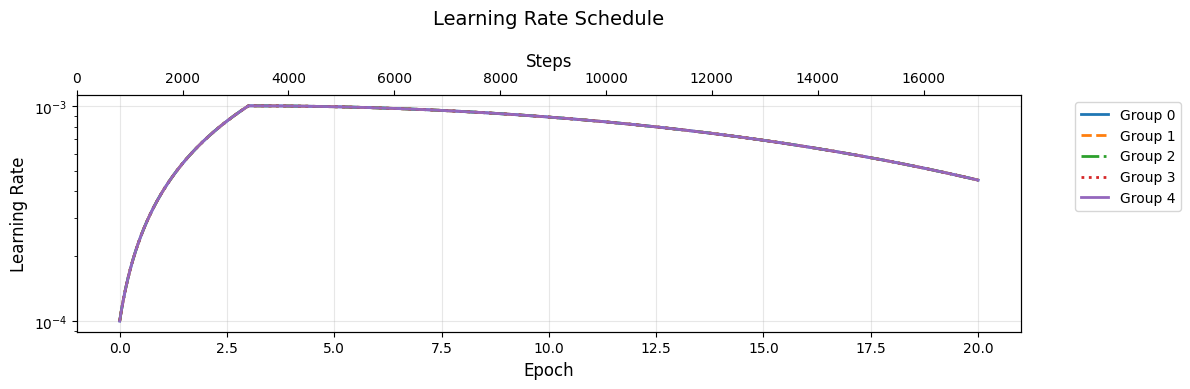

In [40]:
test_scheduler = create_scheduler(
    optimizer=trainer.optimizer,
    scheduler_config=config['scheduler'],
    train_loader=train_loader,
    gradient_accumulation_steps=config['training']['gradient_accumulation_steps']
)

plot_lr_schedule(
    scheduler=test_scheduler,
    num_epochs=20,
    train_loader=train_loader,
    gradient_accumulation_steps=config['training']['gradient_accumulation_steps']
)

#### Setting up the scheduler

In [41]:
trainer.scheduler = create_scheduler(
    optimizer=trainer.optimizer,
    scheduler_config=config['scheduler'],
    train_loader=train_loader,
    gradient_accumulation_steps=config['training']['gradient_accumulation_steps']
)


📈 Configuring Learning Rate Scheduler:
├── Type: COSINE
├── Cosine Annealing Settings:
│   ├── T_max: 32 epochs (28544 steps)
│   └── Min LR: 1e-06
├── Warmup Settings:
│   ├── Duration: 3 epochs (2676 steps)
│   ├── Start Factor: 0.1
│   └── End Factor: 1.0


#### Train
- Set your epochs and start training!
- `NOTE`: The optimizer and scheduler have to be set on the trainer before this call, as in the cells above.

In [42]:
trainer.train(train_loader, val_loader, epochs=35)


📊 Metrics (Epoch 0):
├── TRAIN:
│   ├── ce_loss: 5.6337
│   ├── ctc_loss: 6.3862
│   ├── joint_loss: 7.5496
│   ├── perplexity_char: 6.0561
│   └── perplexity_token: 279.7005
└── VAL:
    ├── cer: 76.2743
    ├── wer: 103.8477
    └── word_dist: 61.7313
└── TRAINING:
    └── learning_rate: 0.000400


wandb: WARNING Saving files without folders. If you want to preserve subdirectories pass base_path to wandb.save, i.e. wandb.save("/mnt/folder/file.h5", base_path="/mnt")
wandb: WARNING Symlinked 1 file into the W&B run directory; call wandb.save again to sync new files.
wandb: WARNING Symlinked 1 file into the W&B run directory; call wandb.save again to sync new files.
wandb: WARNING Symlinked 1 file into the W&B run directory; call wandb.save again to sync new files.



📊 Metrics (Epoch 1):
├── TRAIN:
│   ├── ce_loss: 4.7124
│   ├── ctc_loss: 4.5901
│   ├── joint_loss: 6.0894
│   ├── perplexity_char: 4.5110
│   └── perplexity_token: 111.3189
└── VAL:
    ├── cer: 81.8273
    ├── wer: 128.3668
    └── word_dist: 66.2250
└── TRAINING:
    └── learning_rate: 0.000700


wandb: WARNING Symlinked 1 file into the W&B run directory; call wandb.save again to sync new files.



📊 Metrics (Epoch 2):
├── TRAIN:
│   ├── ce_loss: 3.6002
│   ├── ctc_loss: 2.5696
│   ├── joint_loss: 4.3710
│   ├── perplexity_char: 3.1612
│   └── perplexity_token: 36.6038
└── VAL:
    ├── cer: 38.3689
    ├── wer: 58.7393
    └── word_dist: 31.3438
└── TRAINING:
    └── learning_rate: 0.001000


...

wandb: WARNING Symlinked 1 file into the W&B run directory; call wandb.save again to sync new files.



📊 Metrics (Epoch 33):
├── TRAIN:
│   ├── ce_loss: 1.1925
│   ├── ctc_loss: 0.3478
│   ├── joint_loss: 1.2968
│   ├── perplexity_char: 1.4641
│   └── perplexity_token: 3.2953
└── VAL:
    ├── cer: 6.0550
    ├── wer: 14.4904
    └── word_dist: 4.9000
└── TRAINING:
    └── learning_rate: 0.000003


wandb: WARNING Symlinked 1 file into the W&B run directory; call wandb.save again to sync new files.



📊 Metrics (Epoch 34):
├── TRAIN:
│   ├── ce_loss: 1.1800
│   ├── ctc_loss: 0.3457
│   ├── joint_loss: 1.2837
│   ├── perplexity_char: 1.4582
│   └── perplexity_token: 3.2543
└── VAL:
    ├── cer: 6.0086
    ├── wer: 14.3676
    └── word_dist: 4.8625
└── TRAINING:
    └── learning_rate: 0.000001


wandb: WARNING Symlinked 1 file into the W&B run directory; call wandb.save again to sync new files.


#### Inference



##### W&B Run Tracking for Kaggle Submission

The W&B run is tracked automatically when you train and load
checkpoints using the provided trainer.

Normally, leave `KAGGLE_WANDB_RUN_OVERRIDE = None`.

If you manually replace model weights using
`model.load_state_dict(...)` instead of `trainer.load_checkpoint(...)`,
set `KAGGLE_WANDB_RUN_OVERRIDE` to the exact W&B run that produced
those weights. Manual weight loading does not update the model's
stored W&B association.

Format: `"entity/project/run_id"`

The inference cell ends the trainer's W&B run (`trainer.cleanup()`).
To continue training afterward, first rerun the cells from
`trainer = ASRTrainer(...)` through the scheduler setup. The new
trainer starts a new W&B run. Then reset the override to `None`
before generating a new Kaggle submission, so the trainer can use
the run associated with the new training.

In [43]:
# Optional W&B provenance override for this Kaggle submission.
# Normally, leave this as None.
KAGGLE_WANDB_RUN_OVERRIDE = None

In [44]:
# DO NOT CHANGE ================================

# Clear results from any previous inference attempt.
KAGGLE_SUBMISSION_MESSAGE = None
results_df = None

# Check provenance before running inference.
KAGGLE_SUBMISSION_MESSAGE = trainer.build_kaggle_submission_message(
    homework_tag="HW3P2",
    manual_wandb_run=KAGGLE_WANDB_RUN_OVERRIDE,
)
# ===============================================
 
# Define the recognition config: Greedy search
recognition_config = {
    'num_batches': None,
    'temperature': 1.0,
    'repeat_penalty': 1.0,
    'beam_width': 5, # Beam width of 1 reverts to greedy
}

# Recognize with the config above
config_name = "test"
print(f"Evaluating with {config_name} config")
results = trainer.recognize(test_loader, recognition_config, config_name=config_name, max_length=max_transcript_len)

# Calculate metrics on full batch
generated = [r['generated'] for r in results]
results_df = pd.DataFrame(
    {
        'id': range(len(generated)),
        'transcription': generated,
    }
)

print("Kaggle submission tracking:")
print(KAGGLE_SUBMISSION_MESSAGE)

# Cleanup (will end the active W&B run. To train again, create a new trainer first)
trainer.cleanup()

Evaluating with test config


Kaggle submission tracking:
HW3P2|WB=nregis552-carnegie-mellon-university/Set-Project-Name-Here/g7rthpqi


learning_rate,▄▆██████▇▇▇▇▆▆▆▆▅▅▅▄▄▃▃▃▃▂▂▂▂▁▁▁▁▁▁
train/ce_loss,█▇▅▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/ctc_loss,█▆▄▃▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/joint_loss,█▆▄▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/perplexity_char,█▆▄▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/perplexity_token,█▄▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val/cer,▇█▄▂▂▂▂▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val/wer,▆█▄▂▂▂▂▂▂▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val/word_dist,▇█▄▂▂▂▂▁▂▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
learning_rate,0.0
train/ce_loss,1.17998


## Submit to Kaggle

In [45]:
# DO NOT CHANGE
if (
    globals().get("results_df") is None
    or not globals().get("KAGGLE_SUBMISSION_MESSAGE")
):
    raise RuntimeError("Run the inference cell successfully before submitting.")

results_df.to_csv("results.csv", index=False)

api.competition_submit(
    file_name="results.csv",
    message=KAGGLE_SUBMISSION_MESSAGE,
    competition="f-26-hw-3-p-2-student-competition",
)

100%|██████████| 290k/290k [00:00<00:00, 400kB/s]


{"message": "Successfully submitted to 11785 HW3P2 ASR with Transformer Fall 2026", "ref": 57778644}

##### View the associated W&B run

After submitting, open the competition's **Submissions** tab.
The description beneath each submission shows its associated W&B run:

`HW3P2|WB=entity/project/run_id`

To open that run in W&B, use:

`https://wandb.ai/entity/project/runs/run_id`

This lets you identify which experiment produced each Kaggle submission.


#### **Manual submission (optional)**

If automatic submission is unavailable, download the CSV and submit it manually using one of the options below.

When submitting manually, copy the exact **KAGGLE_SUBMISSION_MESSAGE** printed above into the Kaggle submission description. This information is required to associate the submission with the W&B experiment used to generate it.

##### **Kaggle**

* After running the cell above, the file **`results.csv`** will be saved in:
  **Right sidebar → Output → `kaggle/working/<your repo>/`**
* If the file does not appear right away, click the **refresh icon** in the top-right corner of the Output panel.
* Once the file is visible, **right-click → Download**.
* Upload the downloaded file to the **Kaggle competition submission page**.

---

##### **Colab**

```python
from google.colab import files
files.download("results.csv")
```

##### **PSC**

* Open the left file browser.
* Navigate to:
  `/jet/home/<your_username>/<your repo>/`
* Locate **`results.csv`**.
* Right-click the file and select **Download**.
* If the file does not appear immediately, refresh the file browser.

## 📦 Gradescope Submission Instructions (Read Carefully)

This section guides you through creating and submitting your **final Gradescope code submission**.
Please follow each step in order. Skipping steps may result in an incomplete or invalid submission.

### ⏰ Important Deadlines

* **Kaggle Final Deadline:** See the course schedule
* **Gradescope Code Submission Deadline:**
  **48 hours after** the Kaggle deadline (or the same day as your Slack Kaggle submission, if applicable)

You must submit **both**:

1. A valid Kaggle submission
2. A complete Gradescope code submission zip

Please assign your **final trained model** to the global variable `MODEL`.

We will use this variable to automatically generate a file named
`model_metadata.json`, which records important information about your model (such as parameter count and architecture).

#### 🔴 Important Requirements

* **`MODEL` must be the exact model used for your best Kaggle submission**
* This step is **required** for grading and audit purposes
* If the model does not match your Kaggle submission, your score may be invalidated

#### 🕒 When to Do This

* Run this cell **only after you have finished training** your final model
* Do **not** retrain or modify the model after assigning it to `MODEL`


### Step 1: Confirm Your Final Model

Keep `MODEL = trainer.model` when the current trainer contains
the model used for your best Kaggle submission.

The final submission cell prints the best scored Kaggle submission
and its W&B run. If that submission used a different model,
load its checkpoint into the trainer and rerun the MODEL cell
before recreating the ZIP.

Normally, no change is needed. Changing MODEL does not change
which W&B runs are selected.

In [47]:
MODEL = trainer.model 

### Step 2: Complete the README Section

Fill in the `README` variable with a brief description of your work:

* **Model**: Architecture and key design choices
* **Training Strategy**: Optimizer, scheduler, loss, etc.
* **Augmentations**: If used (omit if not)
* **Notebook Execution**: Any instructions needed to run your notebook

This README will be included in your submission zip.

In [48]:
README = """
- **Model**: Encoder-decoder Transformer with pre-norm blocks, about 16.6M trainable parameters. The front end is two 3x3 Conv2d layers with stride 2 in time each (4x time reduction), followed by a linear projection to d_model = 256. The encoder has 8 layers and the decoder has 4, both with 4 attention heads, RMSNorm inside the blocks and a SwiGLU feed-forward (d_ff = 1024, hidden size 682). Position information comes from rotary embeddings (RoPE) in the self-attention of both stacks; cross-attention has no positional encoding. I also used QK-norm (RMSNorm on the per-head queries and keys). Each stack ends with a LayerNorm. A CTC head (Linear + LogSoftmax) on the encoder output is used only for the auxiliary loss. The decoder embedding and the output projection share weights. Tokenizer: the provided 1k BPE tokenizer.
- **Training Strategy**: AdamW with lr 1e-3 and weight decay 0.01, batch size 32, no gradient accumulation, fp16 mixed precision with GradScaler. LR schedule: linear warmup from 1e-4 to 1e-3 over 3 epochs, then cosine decay to 1e-6 over the remaining 32 epochs, stepped every batch, 35 epochs total. Loss: cross-entropy with label smoothing 0.1 (padding ignored) plus 0.3 x CTC loss (blank = pad token). Regularization: dropout 0.1 and LayerDrop 0.05 in both stacks. Features use global mean/variance normalization computed on the training set. Validation during training uses greedy decoding on the first 5 val batches; the Kaggle predictions use beam search with beam width 5. This setup scored 5.14 on the public Kaggle leaderboard.
- **Augmentations**: SpecAugment on training batches only (in collate_fn): 2 frequency masks of up to 10 bins and 2 time masks of up to 40 frames. No augmentation on val or test.
- **Notebook Execution**: Trained on Colab Pro (A100). Clone the repo and chdir into it, run the pip install cell, and download the Kaggle dataset to /content/hw3p2-data (config.yaml uses root /content/hw3p2-data/hw3p2_data). Then run the cells in order. All hyperparameters are in the config.yaml cell. trainer.train runs 35 epochs, and the inference cell decodes test-clean with beam width 5 and writes results.csv.
"""

### Step 3: Provide Required Credentials

Ensure the following variables are correctly set:

* `KAGGLE_USERNAME`
* `KAGGLE_API_KEY`: the same `KGAT_` token you used to log in to Kaggle
* `WANDB_API_KEY`
* `WANDB_USERNAME_OR_TEAMNAME`
* `WANDB_PROJECT`

These are used **only** to:

* Fetch your official Kaggle score
* Retrieve top W&B runs associated with your Kaggle submissions for grading and audit purposes.

By default, the backend selects up to 10 distinct W&B runs according to the homework's Kaggle score ordering. You may optionally customize the selected list using **FINAL_WANDB_RUNS_OVERRIDE** (see the next cell).

⚠️ Do **not** share your API keys publicly.

In [52]:
# @title
KAGGLE_USERNAME = "regisndahirongoga" # TODO
from getpass import getpass
KAGGLE_API_KEY  = getpass("Kaggle KGAT_ token: ") # TODO: the same API token that starts with KGAT_
WANDB_API_KEY   = getpass("W&B API key: ") # TODO
WANDB_USERNAME_OR_TEAMNAME = "nregis552-carnegie-mellon-university" # TODO: Put your username-or-team-name here
WANDB_PROJECT              = "Set-Project-Name-Here" # TODO: Put your project-name

##### **Optional W&B Run Selection Override**

By default, the submission backend automatically selects up to **10 distinct W&B runs** associated with your eligible Kaggle submissions, ordered according to the official Kaggle metric for this homework.

**In normal use, leave `FINAL_WANDB_RUNS_OVERRIDE = []`.**

Only modify this list if you intentionally want to change the automatically selected W&B runs after reviewing the selection printed by the final submission cell.

Each entry must use the exact format:

`"entity/project/run_id"`

For example:

```python
FINAL_WANDB_RUNS_OVERRIDE = [
    "my-team/HW3P2-F26/abc123xyz",
    "my-team/HW3P2-F26/def456uvw",
]
```
**Requirements:**
- You may specify at most 10 runs.
- Every run must be associated with one of your eligible Kaggle submissions.
- The run associated with your top-ranked Kaggle submission must remain included.
- Leave the list empty to use the automatic selection.

In [ ]:
# Optional:
# Leave this list empty to use the W&B runs selected automatically
# from your eligible Kaggle submissions.
#
# If overriding, provide at most 10 exact W&B run paths using:
#     "entity/project/run_id"
#
# Example:
# FINAL_WANDB_RUNS_OVERRIDE = [
#     "my-team/HW3P2-F26/abc123xyz",
#     "my-team/HW3P2-F26/def456uvw",
# ]
FINAL_WANDB_RUNS_OVERRIDE = []

### Step 4: Set File Paths Correctly

You must provide absolute path to your **final notebook**

### Platform-specific guidance

**Colab**

* Right-click a file in the left file pane → **Copy path**
* Paths typically start with `/content/...`

**Kaggle**

* Download your notebook (`File → Download Notebook`)
* Upload it via **Upload Input → Upload Model**
* Copy paths from the right sidebar (`/kaggle/working/...`)

**PSC / Linux**

* Locate files under `/jet/home/<your_username>/`
* Use `!ls` to confirm paths

Paste the correct path below.

In [53]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [50]:
NOTEBOOK_PATH = "/content/IDL-HW3/HW3P2_Student_Starter_Notebook_F26.ipynb" # TODO

SyntaxError: (unicode error) 'unicodeescape' codec can't decode bytes in position 2-3: truncated \UXXXXXXXX escape (1960576967.py, line 1)

### Step 5: (Optional) Additional Files

If you have extra files you want to include (e.g., config files, scripts), add their paths to `ADDITIONAL_FILES`, Otherwise, leave this list empty.

In [ ]:
ADDITIONAL_FILES = []

### Step 6: Generate the Final Submission Zip

Before running the submission cell:

* Ensure `ACKNOWLEDGED = True`
* Double-check all paths and credentials
* Confirm your Kaggle submission exists

Then run the cell below.
This should generate a `HW3P2_final_submission.zip` which includes:
* Your notebook
* `model_metadata.json`
* README
* WandB run exports
* Kaggle metadata
* Academic integrity acknowledgement

In [ ]:
#### DO NOT MODIFY ####
!git clone https://github.com/CMU-IDeeL/HWP2-Submission-Backend-Student-New.git
!mv HWP2-Submission-Backend-Student-New/submission .
!rm -rf HWP2-Submission-Backend-Student-New
from submission.submission_config import SubmissionConfig
from submission.backend_config import BackendConfig, HW3P2_BACKEND_CONFIG
from submission.main import create_submission_zip

create_submission_zip(
    cfg = SubmissionConfig(
        model = MODEL,
        kaggle_username     = KAGGLE_USERNAME,
        kaggle_api_key      = KAGGLE_API_KEY,
        wandb_api_key       = WANDB_API_KEY,
        wandb_entity        = WANDB_USERNAME_OR_TEAMNAME,
        wandb_project       = WANDB_PROJECT,
        wandb_runs_override = FINAL_WANDB_RUNS_OVERRIDE,
        acknowledged        = ACKNOWLEDGED,
        readme              = README,
        notebook_path       = NOTEBOOK_PATH,
        additional_files    = ADDITIONAL_FILES
    ),
    backend_cfg = HW3P2_BACKEND_CONFIG
)

### Step 7: Upload to Gradescope

1. Download `HW3P2_final_submission.zip`
2. Upload it to **Gradescope**
3. Verify the upload succeeds

⚠️ Submitting an incomplete zip or modifying backend code may result in grading penalties or an Academic Integrity Violation.

---

### ✅ Final Checklist

Before submitting, confirm:

* [ ] Kaggle username is valid
* [ ] `model_metadata.json` matches your best run
* [ ] README is complete
* [ ] File paths are correct
* [ ] `ACKNOWLEDGED = True`
* [ ] Final zip downloads successfully